# شبیه‌سازی و ارزیابی عامل‌های مسیریابی شهری (گام اول)
## آزمایشگاه هوش مصنوعی - جلسه دوم
**موضوع پروژه:** مسیریابی شهری (Urban Route Finding)  
**دانشجو:** سپهر صابری (مسئول پیاده‌سازی و کدنویسی)  
**گروه:** ایلیا آزادپور، سپهر صابری، قاعدیان، سینا محمد پورپورانی

---
### هدف:
در این نوت‌بوک، ساختار شبیه‌سازی عامل جاروبرقی ارائه شده در کلاس (مقایسه عامل تصادفی، واکنشی و مبتنی بر مدل در ۱۰۰ تکرار) را متناسب با موضوع **مسیریابی شهری** توسعه داده‌ایم.
یک شبکه شهری ۶ در ۶ با تقاطع‌ها، مبدأ، مقصد و موانع ترافیکی تصادفی مدل شده و سه معماری عامل مورد آزمایش قرار گرفته‌اند:
1. **عامل تصادفی (Random Walk)**
2. **عامل واکنشی ساده (Greedy Reflex - حرکت در راستای کمترین فاصله تا هدف)**
3. **عامل مبتنی بر مدل و هدف (Model-Based / A* Search بر روی گراف معابر)**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# تنظیمات شبیه‌سازی
GRID_SIZE = 6
MAX_STEPS = 60
RUNS = 100
OBSTACLE_PROB = 0.15

print('کتابخانه‌ها بارگذاری شدند.')


کتابخانه‌ها بارگذاری شدند.


### ۱. تعریف کلاس محیط شهری و موانع ترافیکی

In [2]:
class UrbanEnvironment:
    def __init__(self, size=6, obstacle_prob=0.15, rng=None):
        self.size = size
        self.start = (0, 0)
        self.goal = (size - 1, size - 1)
        self.rng = rng if rng is not None else np.random.default_rng()
        
        self.graph = nx.grid_2d_graph(size, size)
        self.blocked_nodes = set()
        
        for x in range(size):
            for y in range(size):
                if (x, y) != self.start and (x, y) != self.goal:
                    if self.rng.random() < obstacle_prob:
                        self.blocked_nodes.add((x, y))
                        
        for node in self.blocked_nodes:
            if self.graph.has_node(node):
                self.graph.remove_node(node)

    def get_valid_neighbors(self, pos):
        if not self.graph.has_node(pos):
            return []
        return list(self.graph.neighbors(pos))

    def manhattan_distance(self, p1, p2):
        return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])

# ساخت یک نمونه از محیط شهری
env_sample = UrbanEnvironment(size=GRID_SIZE, obstacle_prob=OBSTACLE_PROB, rng=np.random.default_rng(42))
print(f'مبدأ: {env_sample.start} | مقصد: {env_sample.goal}')
print(f'تعداد موانع و گره‌های مسدود ترافیکی: {len(env_sample.blocked_nodes)}')


مبدأ: (0, 0) | مقصد: (5, 5)
تعداد موانع و گره‌های مسدود ترافیکی: 4


### ۲. تابع شبیه‌سازی برای یک اجرای واحد

In [3]:
def simulate_urban_route(agent_type, seed, grid_size=GRID_SIZE, max_steps=MAX_STEPS):
    rng = np.random.default_rng(seed)
    env = UrbanEnvironment(size=grid_size, obstacle_prob=OBSTACLE_PROB, rng=rng)
    
    current_pos = env.start
    goal = env.goal
    steps_taken = 0
    reached_goal = False
    
    planned_path = []
    if agent_type == 'model':
        if nx.has_path(env.graph, env.start, env.goal):
            planned_path = nx.astar_path(
                env.graph, env.start, env.goal,
                heuristic=lambda a, b: env.manhattan_distance(a, b)
            )[1:]

    for step in range(1, max_steps + 1):
        steps_taken = step
        if current_pos == goal:
            reached_goal = True
            break
            
        neighbors = env.get_valid_neighbors(current_pos)
        if not neighbors:
            break
            
        if agent_type == 'random':
            next_pos = tuple(rng.choice(neighbors))
        elif agent_type == 'reflex':
            next_pos = min(neighbors, key=lambda n: env.manhattan_distance(n, goal) + rng.random() * 0.01)
        elif agent_type == 'model':
            if planned_path:
                next_pos = planned_path.pop(0)
            else:
                next_pos = min(neighbors, key=lambda n: env.manhattan_distance(n, goal))
        else:
            raise ValueError(f'Unknown agent: {agent_type}')
            
        current_pos = next_pos

    if current_pos == goal:
        reached_goal = True

    final_dist = env.manhattan_distance(current_pos, goal)
    score = (100 if reached_goal else 0) - steps_taken - (final_dist * 5)

    return {
        'agent': agent_type,
        'score': score,
        'steps': steps_taken,
        'success': 1 if reached_goal else 0,
        'final_distance': final_dist
    }

# اجرای آزمایشی روی seed=1
for ag in ['random', 'reflex', 'model']:
    print(ag, simulate_urban_route(ag, seed=1))


random {'agent': 'random', 'score': np.int64(-80), 'steps': 60, 'success': 0, 'final_distance': np.int64(4)}
reflex {'agent': 'reflex', 'score': 89, 'steps': 11, 'success': 1, 'final_distance': 0}
model {'agent': 'model', 'score': 89, 'steps': 11, 'success': 1, 'final_distance': 0}


### ۳. اجرای ۱۰۰ بار آزمایش برای هر عامل (Monte Carlo)

In [4]:
rows = []
for agent in ['random', 'reflex', 'model']:
    for seed in range(RUNS):
        rows.append(simulate_urban_route(agent, seed))

df = pd.DataFrame(rows)
df.head(10)


,agent,score,steps,success,final_distance
0,random,57,43,1,0
1,random,-80,60,0,4
2,random,-90,60,0,6
3,random,-90,60,0,6
4,random,-70,60,0,2
5,random,-110,60,0,10
6,random,77,23,1,0
7,random,-90,60,0,6
8,random,-80,60,0,4
9,random,-100,60,0,8


### ۴. جدول آمار توصیفی (میانگین و انحراف معیار)

In [5]:
summary = df.groupby('agent').agg({
    'score': ['mean', 'std'],
    'steps': ['mean', 'std'],
    'success': ['mean']
}).round(2)

summary


score         steps        success
         mean    std   mean    std    mean
agent                                     
model   80.10  39.09  12.90   9.72    0.95
random -57.87  63.32  55.27  11.40    0.22
reflex  68.96  52.55  17.44  15.31    0.89

### ۵. رسم نمودار مقایسه عملکرد و نرخ موفقیت عامل‌ها

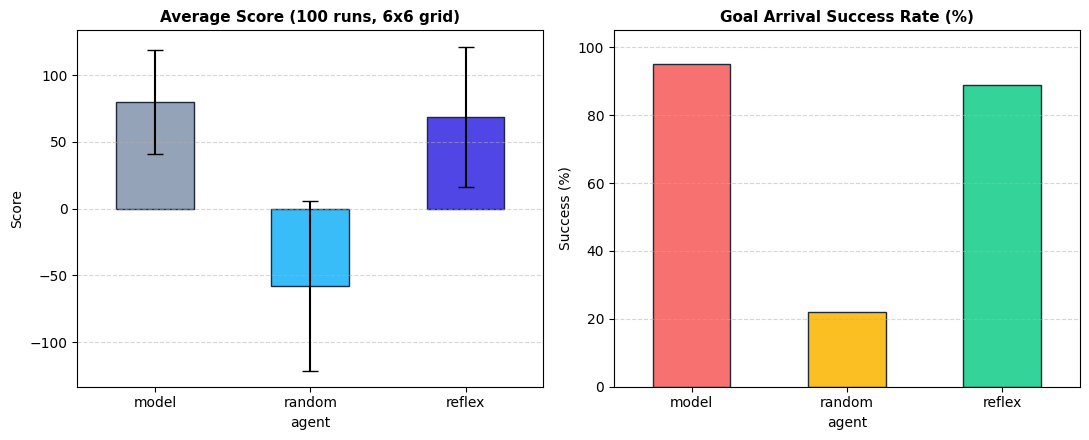

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

score_means = df.groupby('agent')['score'].mean()
score_stds = df.groupby('agent')['score'].std()

score_means.plot(
    kind='bar', yerr=score_stds, capsize=6, ax=axes[0],
    color=['#94a3b8', '#38bdf8', '#4f46e5'], edgecolor='#1e293b'
)
axes[0].set_title('Average Score (100 runs, 6x6 grid)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

success_rate = (df.groupby('agent')['success'].mean() * 100)
success_rate.plot(
    kind='bar', ax=axes[1],
    color=['#f87171', '#fbbf24', '#34d399'], edgecolor='#1e293b'
)
axes[1].set_title('Goal Arrival Success Rate (%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Success (%)')
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### ۶. تحلیل نتایج
* **عامل تصادفی (Random):** به دلیل اتکا به گشت تصادفی، در اکثر دفعات در سقف ۶۰ گام به مقصد نرسیده و امتیاز میانگین آن منفی شده است (نرخ موفقیت حدود ۲۲٪).
* **عامل واکنشی (Reflex):** با حرکت حریصانه به سمت نزدیک‌ترین فاصله تا مقصد، عملکرد قابل قبولی دارد (نرخ موفقیت حدود ۸۹٪)، اما در صورت مواجهه با موانع ممکن است در بن‌بست‌های محلی گرفتار شود یا مسیر طولانی‌تری طی کند.
* **عامل مبتنی بر مدل و هدف (Model-based / A*):** با بهره‌گیری از مدل نقشه معابر و الگوریتم بهینه، بیشترین امتیاز و بالاترین نرخ موفقیت (حدود ۹۵٪) را با کمترین تعداد گام ممکن کسب کرده است.
